# Threshold aware agent scoring

Notebook codifying a combined score that combines multiple factors into a single scaled value.


In [2]:
# let's create the threshold loss function
import numpy as np
import pandas as pd
import math


def softplus(z):
    """
    Smooth version of max(0, z).

    softplus(z) = log(1 + exp(z))
    """
    return np.logaddexp(0, z)

def threshold_loss(x, k=10):
    """
    Convex threshold penalty.

    x < 1  means inside the acceptable region.
    x == 1 means exactly at the threshold.
    x > 1  means outside the acceptable region.

    P(x) = softplus(k * (x - 1))^2
    """
    return softplus(k * (x - 1)) ** 2

In [3]:
# configs
metric_config = {
    "cost": {
        "column": "cost_usd",
        "direction": "lower_is_better",
        "tau": 0.10,
        "k": 2,
        "lambda": 1.0,
    },
    "latency": {
        "column": "latency_seconds",
        "direction": "lower_is_better",
        "tau": 5.0,
        "k": 2,
        "lambda": 1.0,
    },
    "quality": {
        "column": "quality_score",
        "direction": "higher_is_better",
        "tau": 0.80,
        "k": 2,
        "lambda": 2.0,
    },
}

compare the average results vs the path results by score.  why isn't this good enough?  


In [4]:
def normalized_badness(series, tau, direction):
    """
    Convert every metric into normalized badness.

    x < 1  is good
    x = 1  is at the threshold
    x > 1  is bad
    """

    if direction == "lower_is_better":
        return series / tau

    if direction == "higher_is_better":
        return (1 - series) / (1 - tau)

    raise ValueError(f"Unknown direction: {direction}")

In [5]:
def aggregate_losses(losses, method="l2_norm"):
    losses = np.asarray(losses)

    if method == "sum":
        return losses.sum(axis=-1)

    if method == "l2_norm":
        return np.linalg.norm(losses, ord=2, axis=-1)

    if method == "max":
        return losses.max(axis=-1)

    raise ValueError(f"Unknown aggregation method: {method}")

def score_traces(df, metric_config, score_name="threshold_score", method="l2_norm"):
    """
    Score many traces at once.

    Returns a copy of df with added columns:
      - <metric>_x
      - <metric>_loss
      - <metric>_weighted_loss
      - <metric>_inside_box
      - threshold_score
      - inside_box
    """

    scored = df.copy()
    weighted_loss_columns = []
    inside_box_columns = []
    lambda_sum = sum(config["lambda"] for config in metric_config.values())
    # reference score at threshold corner: x_f = 1 for all factors
    reference_losses = []
    
    for metric_name, config in metric_config.items():
        value = scored[config["column"]]

        x = normalized_badness(
            series=value,
            tau=config["tau"],
            direction=config["direction"],
        ) # this adjusts the loss for tau, the threshold

        loss = threshold_loss(
            x=x,
            k=config["k"],
        ) # k adjusts the convexity.  bigger k means crossing the threshold is very costly

        lambda_normalized = config["lambda"]/lambda_sum 
        #lambda is the factor weight.  normalized to add to one.  
        #lambda can be especially important inside the box, below the threshold, before k takes over
        
        weighted_loss = lambda_normalized * loss

        x_col = f"{metric_name}_x"
        loss_col = f"{metric_name}_loss"
        weighted_col = f"{metric_name}_weighted_loss"
        inside_col = f"{metric_name}_inside_box"

        scored[x_col] = x
        scored[loss_col] = loss
        scored[weighted_col] = weighted_loss
        scored[inside_col] = x <= 1

        weighted_loss_columns.append(weighted_col)
        inside_box_columns.append(inside_col)

        reference_loss = threshold_loss(x=1.0, k=config["k"]) #calculating the loss where all normalized factors==1.  The corner of the box
        reference_losses.append(lambda_normalized * reference_loss)

    
    loss_matrix = scored[weighted_loss_columns].to_numpy()
    raw_score = aggregate_losses(loss_matrix, method=method)
    reference_score = aggregate_losses(reference_losses, method=method)
    scored[score_name] = raw_score / reference_score
    """
    losses = scored[weighted_loss_columns].to_numpy()
    if method == "sum":
        scored[score_name] = losses.sum(axis=1)
    if method == "l2_norm":
        scored[score_name] = np.linalg.norm(losses,ord=2,axis=1,)
    if method == "max":
        scored[score_name] = losses.max(axis=1)
    """
    scored["inside_box"] = scored[inside_box_columns].all(axis=1)

    return scored

In [6]:
traces = pd.DataFrame(
    [
        {"trace_id": 1, "config": "small_model", "cost_usd": 0.03, "latency_seconds": 2.1, "quality_score": 0.74},
        {"trace_id": 2, "config": "small_model", "cost_usd": 0.04, "latency_seconds": 2.8, "quality_score": 0.81},
        {"trace_id": 3, "config": "large_model", "cost_usd": 0.14, "latency_seconds": 6.2, "quality_score": 0.91},
        {"trace_id": 4, "config": "large_model", "cost_usd": 0.11, "latency_seconds": 4.9, "quality_score": 0.89},
    ]
)

scored = score_traces(traces, metric_config)

scored[
    [
        "trace_id",
        "config",
        "cost_x",
        "latency_x",
        "quality_x",
        "inside_box",
        "threshold_score",
    ]
]

,trace_id,config,cost_x,latency_x,quality_x,inside_box,threshold_score
0,1,small_model,0.3,0.42,1.30,False,1.830792
1,2,small_model,0.4,0.56,0.95,True,0.715488
2,3,large_model,1.4,1.24,0.45,False,1.412549
3,4,large_model,1.1,0.98,0.55,False,0.693210


SQL version - easy to import traces

In [7]:
import sqlite3
use_sql = False
if use_sql:
    conn = sqlite3.connect("agent_traces.db")
    
    traces = pd.read_sql_query(
        """
        select
            trace_id,
            config_name as config,
            cost_usd,
            latency_seconds,
            quality_score
        from trace_results
        """,
        conn,
    )
    
    scored = score_traces(traces, metric_config)

In [8]:
def RMSLoss(scores)->float:
    """
    calculates the root mean squared loss root((squared(x))_bar) = sqrt(squared(x_bar) + var(x))
    Interpretable as a single scalar that combined both mean loss and variance of loss.
    for scores with the same mean, a higher variance is worse.
    Should be sound for normal-like distributions, so scores should be log-normal-like
    returned value will be on the same scale as the raw mean
    """
    _log_scores = np.log(scores)+1 
    #convert to log, then add one to avoid negative numbers.  
    #log scores are squared in next step, which would mean very negative (low loss) is increasingly penalized.
    _RMSL = np.sqrt(np.square(np.mean(_log_scores)) + np.var(_log_scores,ddof=1))
    return np.exp(_RMSL-1)

def p95(x):
    return x.quantile(0.95)

def outside_box_rate(x):
    return 1 - x.mean()

In [9]:
def standard_summary(scored)-> pd.Dataframe:
    summary = (
        scored
        .groupby("config")
        .agg(
            traces=("trace_id", "count"),
            RMSL=("threshold_score",RMSLoss),
            mean_score=("threshold_score", "mean"),
            median_score=("threshold_score", "median"),
            inside_box_rate=("inside_box", "mean"),
            mean_cost=("cost_usd", "mean"),
            mean_latency=("latency_seconds", "mean"),
            mean_quality=("quality_score", "mean"),
        )
        .sort_values(["inside_box_rate", "mean_score"], ascending=[False, True])
    )
    return summary

summary = standard_summary(scored)
summary

,traces,RMSL,mean_score,median_score,inside_box_rate,mean_cost,mean_latency,mean_quality
config,,,,,,,,
small_model,2,1.370426,1.273140,1.273140,0.5,0.035,2.45,0.775
large_model,2,1.116442,1.052879,1.052879,0.0,0.125,5.55,0.900


In [10]:
scored

,trace_id,config,cost_usd,latency_seconds,quality_score,cost_x,cost_loss,cost_weighted_loss,cost_inside_box,latency_x,latency_loss,latency_weighted_loss,latency_inside_box,quality_x,quality_loss,quality_weighted_loss,quality_inside_box,threshold_score,inside_box
0,1,small_model,0.03,2.1,0.74,0.3,0.048584,0.012146,True,0.42,0.074357,0.018589,True,1.30,1.076381,0.538191,False,1.830792,False
1,2,small_model,0.04,2.8,0.81,0.4,0.069318,0.017329,True,0.56,0.120392,0.030098,True,0.95,0.415247,0.207624,True,0.715488,True
2,3,large_model,0.14,6.2,0.91,1.4,1.371477,0.342869,False,1.24,0.924819,0.231205,False,0.45,0.082562,0.041281,True,1.412549,False
3,4,large_model,0.11,4.9,0.89,1.1,0.637026,0.159256,False,0.98,0.453396,0.113349,True,0.55,0.116386,0.058193,True,0.693210,False


### Create random traces

In [11]:
import numpy as np
import pandas as pd

np.random.seed(42)

n = 100

configs = np.random.choice(
    ["small_fast_model", "large_accurate_model"],
    size=n,
    p=[0.5, 0.5],
)

rows = []

for i, config in enumerate(configs, start=1):
    if config == "small_fast_model":
        cost_usd = np.random.normal(loc=0.04, scale=0.015)
        latency_seconds = np.random.normal(loc=2.5, scale=0.8)
        quality_score = np.random.normal(loc=0.78, scale=0.08)

    else:
        cost_usd = np.random.normal(loc=0.12, scale=0.035)
        latency_seconds = np.random.normal(loc=5.5, scale=1.5)
        quality_score = np.random.normal(loc=0.88, scale=0.05)

    rows.append(
        {
            "trace_id": i,
            "config": config,
            "cost_usd": max(cost_usd, 0.001),
            "latency_seconds": max(latency_seconds, 0.1),
            "quality_score": np.clip(quality_score, 0, 1),
        }
    )

traces = pd.DataFrame(rows)

traces.head()

,trace_id,config,cost_usd,latency_seconds,quality_score
0,1,small_fast_model,0.041306,2.260794,0.787341
1,2,large_accurate_model,0.050435,5.170492,0.897856
2,3,large_accurate_model,0.171726,4.722595,0.839575
3,4,large_accurate_model,0.102439,6.873103,0.896438
4,5,small_fast_model,0.032054,2.910614,0.787766


In [12]:
scored = score_traces(traces, metric_config)

In [13]:
summary = standard_summary(scored)
summary

,traces,RMSL,mean_score,median_score,inside_box_rate,mean_cost,mean_latency,mean_quality
config,,,,,,,,
small_fast_model,53,1.439468,1.448994,0.873019,0.45283,0.037095,2.756490,0.784559
large_accurate_model,47,1.243741,1.273738,1.064270,0.06383,0.114360,5.620223,0.889537


### Graph of box

In [147]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

def p95(x):
    return pd.Series(x).quantile(0.95)


def draw_threshold_box(ax, limit=1.0):
    """Draw a faint cyan threshold volume with softly glowing edges."""

    corners = np.array([
        [0, 0, 0],
        [limit, 0, 0],
        [limit, limit, 0],
        [0, limit, 0],
        [0, 0, limit],
        [limit, 0, limit],
        [limit, limit, limit],
        [0, limit, limit],
    ])

    face_indices = [
        [0, 1, 2, 3],
        [4, 5, 6, 7],
        [0, 1, 5, 4],
        [2, 3, 7, 6],
        [1, 2, 6, 5],
        [0, 3, 7, 4],
    ]

    box = Poly3DCollection(
        [corners[idx] for idx in face_indices],
        facecolors=(0.40, 0.85, 0.92, 0.025),
        edgecolors="none",
    )
    ax.add_collection3d(box)

    edge_indices = [
        (0, 1), (1, 2), (2, 3), (3, 0),
        (4, 5), (5, 6), (6, 7), (7, 4),
        (0, 4), (1, 5), (2, 6), (3, 7),
    ]

    for start, end in edge_indices:
        points = corners[[start, end]]

        # Broad, faint stroke underneath a crisp edge.
        ax.plot(
            points[:, 0], points[:, 1], points[:, 2],
            color="#83DDE8", linewidth=4, alpha=0.035,
        )
        ax.plot(
            points[:, 0], points[:, 1], points[:, 2],
            color="#83DDE8", linewidth=0.85, alpha=0.60,
        )


def plot_threshold_boxes_by_config(
    df,
    config_col="config",
    axes=("cost_x", "latency_x", "quality_x"),
    score_col="threshold_score",
    agg_name="rms",
    agg_func=RMSLoss,
    box_limit=1.0,
    max_axis=2.0,
    view="threshold_corner",
    figsize_per_col=(6.5, 5.8),
    zoom=1.0,
    tight=False,
    header_text=True,
    colorbar=True,
    title="Which model stays within bounds?",
    subtitle="Cost, latency, and quality loss—measured against shared limits.",
    axis_labels=("Cost", "Latency", "Quality loss"),
):
    """
    Draw one dark-themed 3D threshold-box plot per configuration.

    Colors share a common score scale across configurations.
    The diamond marks mean factor position; its caption reports
    the separately calculated aggregate score.

    `tight` is retained for compatibility. Explicit layout is used
    regardless, to preserve the manually positioned colorbar.
    """

    bg = "#10151F"
    text = "#EDF1F7"
    muted = "#95A2B5"

    cmap = LinearSegmentedColormap.from_list(
        "threshold_hero",
        ["#A99AFF", "#C987DA", "#ED839A", "#FF715B"],
    )

    x_col, y_col, z_col = axes

    # Exclude missing/nonfinite values from plotting and summaries.
    data = df.dropna(subset=[config_col, *axes, score_col]).copy()
    finite = np.isfinite(data[[*axes, score_col]].to_numpy(dtype=float))
    data = data.loc[finite.all(axis=1)]

    configs = list(data[config_col].unique())
    if not configs:
        raise ValueError("No valid rows to plot.")

    if not 0 < box_limit <= max_axis:
        raise ValueError("Require 0 < box_limit <= max_axis.")

    ncols = min(2, len(configs))
    nrows = int(np.ceil(len(configs) / ncols))

    fig = plt.figure(
        figsize=(
            figsize_per_col[0] * ncols + 2,
            figsize_per_col[1] * nrows,
        ),
        facecolor=bg,
    )

    # Fixed-height header/footer space, including for multiple rows.
    height = fig.get_figheight()
    fig.subplots_adjust(
        left=0.1,
        right=0.7,
        bottom=0.95 / height,
        top=1 - 1.5 / height,
        wspace=0.0,
        hspace=0.28,
    )

    fig.text(
        0.07, 1 - 0.22 / height,
        title,
        fontsize=23,
        fontweight="bold",
        color=text,
        va="top",
    )
    fig.text(
        0.07, 1 - 0.65 / height,
        subtitle,
        fontsize=10,
        color=muted,
        va="top",
    )

    score_min = float(data[score_col].min())
    score_max = float(data[score_col].max())
    score_span = max(score_max - score_min, 1e-12)

    norm = Normalize(
        vmin=score_min,
        vmax=score_max if score_max > score_min else score_min + 1,
    )

    for i, config in enumerate(configs, start=1):
        ax = fig.add_subplot(nrows, ncols, i, projection="3d")
        ax.set_facecolor(bg)
        ax.set_proj_type("ortho")
        ax.set_box_aspect((1, 1, 1), zoom=zoom)

        part = data.loc[data[config_col] == config]

        x = part[x_col].to_numpy(dtype=float)
        y = part[y_col].to_numpy(dtype=float)
        z = part[z_col].to_numpy(dtype=float)
        score = part[score_col].to_numpy(dtype=float)

        inside = (
            (x >= 0) & (x <= box_limit)
            & (y >= 0) & (y <= box_limit)
            & (z >= 0) & (z <= box_limit)
        )
        outside = ~inside

        scaled = np.clip((score - score_min) / score_span, 0, 1)
        inside_sizes = 18 + 45 * scaled
        outside_sizes = 28 + 65 * scaled

        draw_threshold_box(ax, limit=box_limit)

        ax.scatter(
            x[inside], y[inside], z[inside],
            c=score[inside],
            cmap=cmap,
            norm=norm,
            s=inside_sizes[inside],
            alpha=0.65,
            marker="o",
            linewidths=0,
            depthshade=False,
        )

        ax.scatter(
            x[outside], y[outside], z[outside],
            c=score[outside],
            cmap=cmap,
            norm=norm,
            s=outside_sizes[outside],
            alpha=0.90,
            marker="x",
            linewidths=1.2,
            depthshade=False,
        )

        agg_score = float(agg_func(part[score_col]))

        ax.scatter(
            [x.mean()], [y.mean()], [z.mean()],
            s=125,
            marker="D",
            c=text,
            edgecolors=bg,
            linewidths=1.4,
            depthshade=False,
        )

        ax.set_title(
            str(config).replace("_", " ").capitalize(),
            loc="left",
            fontsize=15,
            fontweight="bold",
            color=text,
            pad=14,
        )

        if header_text:
            ax.text2D(
                0.0, 0.98,
                f"{inside.mean():.0%} within limits"
                f"  ·  {agg_name.upper()} {agg_score:.3f}"
                f"  ·  n={len(part):,}",
                transform=ax.transAxes,
                va="top",
                fontsize=10,
                color="#C3CDDA",
                #color=muted,
            )

        ax.set_xlabel(axis_labels[0], color=muted, labelpad=7)
        ax.set_ylabel(axis_labels[1], color=muted, labelpad=7)
        ax.set_zlabel(axis_labels[2], color=muted, labelpad=7)

        ax.set_xlim(0, max_axis)
        ax.set_ylim(0, max_axis)
        ax.set_zlim(0, max_axis)

        ticks = sorted(set([0, box_limit, max_axis]))
        ax.set_xticks(ticks)
        ax.set_yticks(ticks)
        ax.set_zticks(ticks)

        ax.tick_params(colors=muted, labelsize=8, pad=0)
        ax.grid(False)

        for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
            axis.pane.fill = False
            axis.pane.set_edgecolor("none")
            axis.pane.set_linewidth(0)
            axis.line.set_color("#465163")

        if view == "threshold_corner":
            ax.view_init(elev=20, azim=-45)
        elif view == "oblique":
            ax.view_init(elev=18, azim=35)
        else:
            raise ValueError(
                "view must be 'oblique' or 'threshold_corner'."
            )

    # Dedicated colorbar axes keep it clear of the 3D panels.
    if colorbar:
        bar_width = 0.50
    
        cax = fig.add_axes([
            0.38 - bar_width / 2,  # Center on the whole figure
            0.60 / height,
            bar_width,
            0.075 / height,
        ])
    
        mappable = ScalarMappable(norm=norm, cmap=cmap)
        cbar = fig.colorbar(
            mappable,
            cax=cax,
            orientation="horizontal",
        )
        cbar.outline.set_visible(False)
        cbar.ax.tick_params(colors=muted, labelsize=8, length=0)
        cbar.set_label(
            "Threshold score · lower is better\n○ Within limits     × Outside limits     ◆ Mean factor position",
            color=muted,
            fontsize=9,
            labelpad=6,
            loc="center",
        )

    return fig

def save_boxes(fig, filename="threshold_hero.png"):
    fig.savefig(
    filename,
    dpi=300,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight",
    pad_inches=0.25,
)

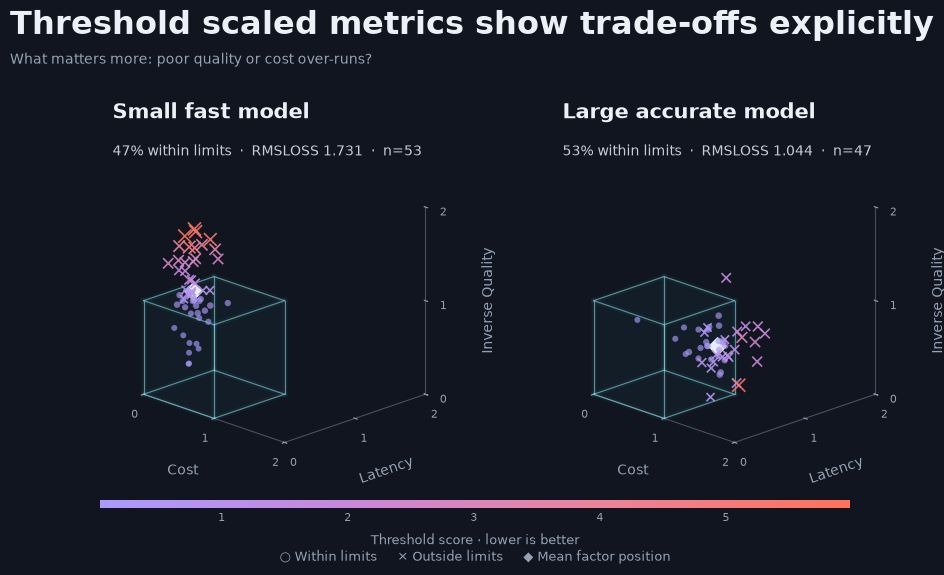

In [170]:
fig = plot_threshold_boxes_by_config(
    scored,
    config_col="config",
    axes=("cost_x", "latency_x", "quality_x"),
    score_col="threshold_score",
    agg_name="rmsloss",
    agg_func=RMSLoss,
    view="threshold_corner",#threshold_corner, oblique
    max_axis=2.0,
    title="Threshold scaled metrics show trade-offs explicitly",
    subtitle="What matters more: poor quality or cost over-runs?",
    axis_labels=("Cost", "Latency", "Inverse Quality"),
)

fig.savefig(
    "figures/threshold_small_vs_large.png",
    dpi=200,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight",
    pad_inches=0.25,
)
plt.show()

On the left you can see that the traces falling outside of the box are long the vertical "quality" axis... meaning that the accuracy of the agent was below and sometimes well below the threshold. While 45% of traces are inside the box, there are some bigger misses. 
On the right, the errors are along the cost and latency axis, but not too many traces that are well outside of the box.  Despite fewer traces inside the box, the scoring is better than the small fast model.  

### playing with the thresholds and weights

In [16]:
metric_config = {
    "cost": {
        "column": "cost_usd",
        "direction": "lower_is_better",
        "tau": 0.12,
        "k": 3,
        "lambda": 1.0,
    },
    "latency": {
        "column": "latency_seconds",
        "direction": "lower_is_better",
        "tau": 7.0,
        "k": 3,
        "lambda": 1.0,
    },
    "quality": {
        "column": "quality_score",
        "direction": "higher_is_better",
        "tau": 0.80,
        "k": 3,
        "lambda": 1.0,
    },
}

In [17]:
scored = score_traces(traces, metric_config)

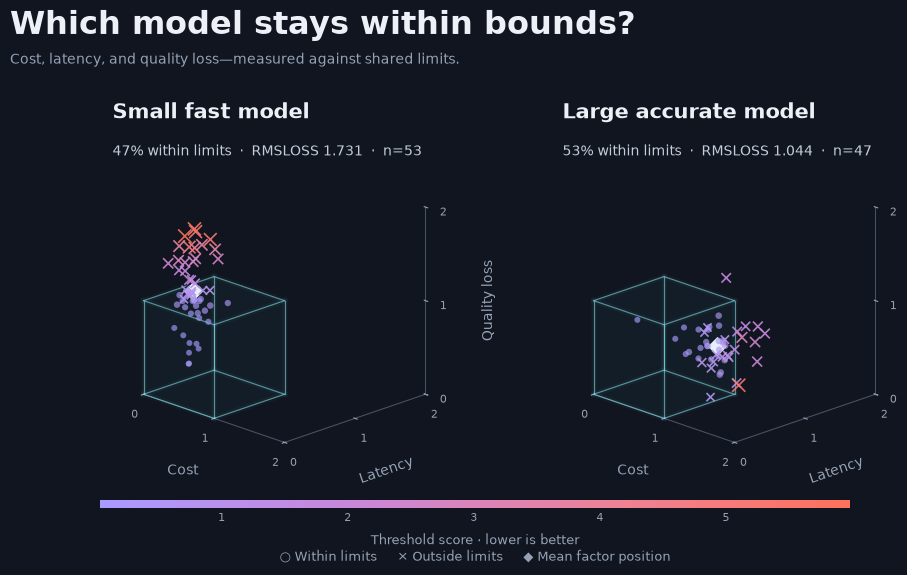

In [183]:
fig = plot_threshold_boxes_by_config(
    scored,
    config_col="config",
    axes=("cost_x", "latency_x", "quality_x"),
    score_col="threshold_score",
    agg_name="rmsloss",
    agg_func=RMSLoss,
    view="threshold_corner",#threshold_corner, oblique
    max_axis=2.0,
)

Above, we've expanded the thresholds to allow for slightly higher prices and a bit more latency, while holding the quality threshold at 80% accuracy.  The result is that more of the traces from the large accurate model are acceptible.  If these are your two choices, it gives you a rational way to approach the trade offs.  ideally, this is a starting point and tuning will follow.

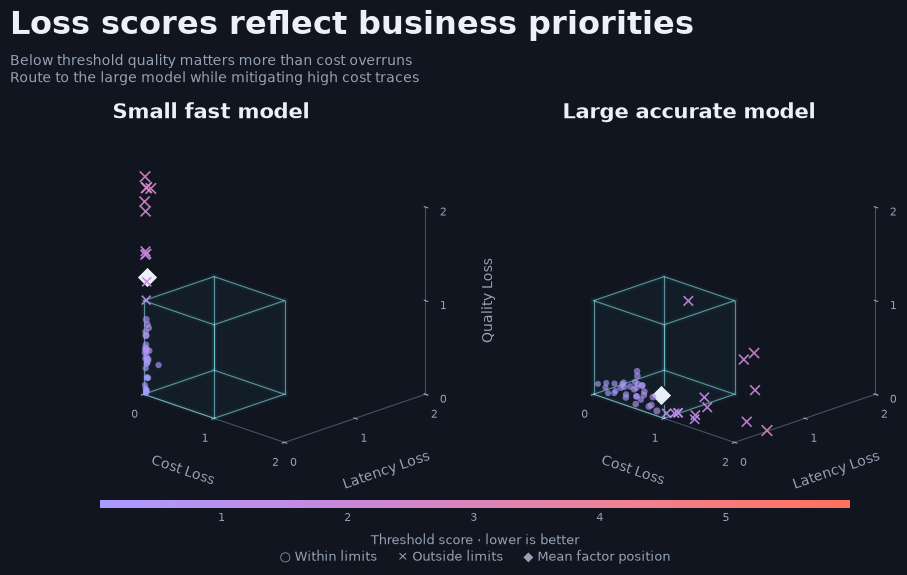

In [182]:
fig = plot_threshold_boxes_by_config(
    scored,
    config_col="config",
    axes=("cost_loss", "latency_loss", "quality_loss"),
    score_col="threshold_score",
    agg_name="rmsloss",
    agg_func=RMSLoss,
    header_text=False,
    colorbar=True,
    zoom=1.0,
    view="threshold_corner",#threshold_corner, oblique
    max_axis=2.0,
    title="Loss scores reflect business priorities",
    subtitle="Below threshold quality matters more than cost overruns\nRoute to the large model while mitigating high cost traces", 
    axis_labels=("Cost Loss", "Latency Loss", "Quality Loss"),
)

fig.savefig(
    "figures/threshold_loss_priorities.png",
    dpi=200,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight",
    pad_inches=0.25,
)
plt.show()

Where before we were looking at the adjusted factor values (cost, latency, quality), above we see the actual weighted scores.  The "inside the box" pct is not terribly meaningful, but it shows where the true weighted losses are occuring.  On the left, there is almost no cost or latency loss - it is consistently a cheap, quick model, but pays the price in quality.  On the right, you can see a greater spread inside the box, but fewer heavily penalized traces outside the box... mostly around excess cost.

In [181]:
summary = (
    scored
    .groupby("config")
    .agg(
        traces=("trace_id", "count"),
        RMSL=("threshold_score",RMSLoss),
        mean_score=("threshold_score", "mean"),
        median_score=("threshold_score", "median"),
        inside_box_rate=("inside_box", "mean"),
        cost_score=("cost_x", "mean"),
        latency_score=("latency_x", "mean"),
        inv_quality_score=("quality_x", "mean"),
        cost_loss=("cost_loss", "mean"),
        latency_loss=("latency_loss", "mean"),
        quality_loss=("quality_loss", "mean"),
    )
    .sort_values(["inside_box_rate", "mean_score"], ascending=[False, True])
)
summary.style.format(precision=2)

,traces,RMSL,mean_score,median_score,inside_box_rate,cost_score,latency_score,inv_quality_score,cost_loss,latency_loss,quality_loss
config,,,,,,,,,,,
large_accurate_model,47,1.04,0.99,0.62,0.53,0.95,0.80,0.55,0.64,0.31,0.08
small_fast_model,53,1.73,1.50,0.63,0.47,0.31,0.39,1.08,0.02,0.03,1.24


In [21]:
scored.head()

,trace_id,config,cost_usd,latency_seconds,quality_score,cost_x,cost_loss,cost_weighted_loss,cost_inside_box,latency_x,latency_loss,latency_weighted_loss,latency_inside_box,quality_x,quality_loss,quality_weighted_loss,quality_inside_box,threshold_score,inside_box
0,1,small_fast_model,0.041306,2.260794,0.787341,0.344214,0.017128,0.005709,True,0.322971,0.015196,0.005065,True,1.063296,0.628201,0.209400,False,0.755397,False
1,2,large_accurate_model,0.050435,5.170492,0.897856,0.420292,0.026193,0.008731,True,0.738642,0.141425,0.047142,True,0.510722,0.042998,0.014333,True,0.180395,True
2,3,large_accurate_model,0.171726,4.722595,0.839575,1.431052,2.358175,0.786058,False,0.674656,0.102249,0.034083,True,0.802123,0.193380,0.064460,True,2.845935,False
3,4,large_accurate_model,0.102439,6.873103,0.896438,0.853654,0.247538,0.082513,True,0.981872,0.443989,0.147996,True,0.517812,0.044680,0.014893,True,0.613206,True
4,5,small_fast_model,0.032054,2.910614,0.787766,0.267113,0.011071,0.003690,True,0.415802,0.025549,0.008516,True,1.061169,0.622685,0.207562,False,0.749016,False


In [22]:
import numpy as np
import pandas as pd


def make_hero_trace_sample(
    n=80,
    max_x=1.8,
    noise=0.03,
    seed=42,
    config_name="hero_demo",
):
    """
    Create synthetic traces running from the origin,
    through the threshold corner, and beyond.

    Assumes normalized badness columns:
        cost_x, latency_x, quality_x

    The threshold box boundary is at x = 1.
    """

    rng = np.random.default_rng(seed)

    t = np.linspace(0, max_x, n)

    traces = pd.DataFrame(
        {
            "trace_id": range(1, n + 1),
            "config": config_name,
            "cost_x": t + rng.normal(0, noise, n),
            "latency_x": t + rng.normal(0, noise, n),
            "quality_x": t + rng.normal(0, noise, n),
        }
    )

    # Keep values from dipping below zero near the origin.
    for col in ["cost_x", "latency_x", "quality_x"]:
        traces[col] = traces[col].clip(lower=0)

    return traces

In [23]:


def score_normalized_traces(df, x_cols=("cost_x", "latency_x", "quality_x"), k=10):
    scored = df.copy()

    loss_cols = []

    for col in x_cols:
        loss_col = col.replace("_x", "_loss")
        scored[loss_col] = threshold_loss(scored[col], k=k)
        loss_cols.append(loss_col)

    scored["threshold_score"] = scored[loss_cols].sum(axis=1)
    scored["inside_box"] = (scored[list(x_cols)] <= 1).all(axis=1)

    return scored

In [57]:
hero = make_hero_trace_sample(n=80, max_x=1.8, noise=0.025,config_name="")
hero_scored = score_normalized_traces(hero, k=3)

#hero_scored.iloc[40:60]

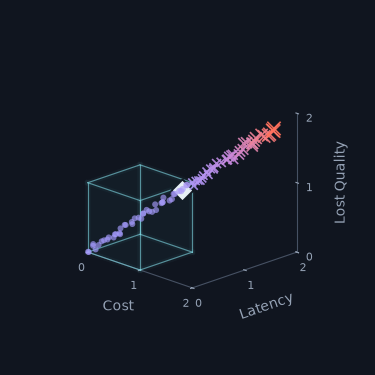

In [171]:
fig = plot_threshold_boxes_by_config(
    hero_scored,
    config_col="config",
    axes=("cost_x", "latency_x", "quality_x"),
    score_col="threshold_score",
    agg_name="RMSLoss",
    agg_func=RMSLoss,
    figsize_per_col=(6, 6),
    zoom=0.7,
    header_text=False,
    colorbar=False,
    view="threshold_corner",#threshold_corner, oblique
    max_axis=2.0,
    title="",
    subtitle="",
    axis_labels=("Cost", "Latency", "Lost Quality"),
)


for ax in fig.axes:
    if ax.name == "3d":  # Leave the colorbar in place
        pos = ax.get_position()
        ax.set_position([
            pos.x0 - 0.18,  # Shift left by 10% of figure width
            pos.y0 + 0.10,
            pos.width,
            pos.height,
        ])
    if ax.name == "rectilinear":  # Leave the colorbar in place
        pos = ax.get_position()
        ax.set_position([
            pos.x0 - 0.15,  # Shift left by 10% of figure width
            pos.y0 + 0.2,
            pos.width,
            pos.height,
        ])

if True:
    #save_boxes(fig, filename="threshold_hero.png")
    fig.savefig(
        "figures/threshold_hero.png",
        dpi=200,
        facecolor=fig.get_facecolor(),
        bbox_inches="tight", #None to preserve exact canvas dims, "tight" to tighten
        pad_inches=0.25,
    )

plt.show()

In [97]:
    
#plt.show()

This shows the locational loss endpoints for for traces with steadily increasing losses. The dot start small and blue to show low loss, then expand in size and trun red as they proceed out of the box through the far corner.  The far corner represents a normalized loss of (1,1,1)... at the threshold on each factor.  The loss is normalized to set loss = 1 at that corner.  

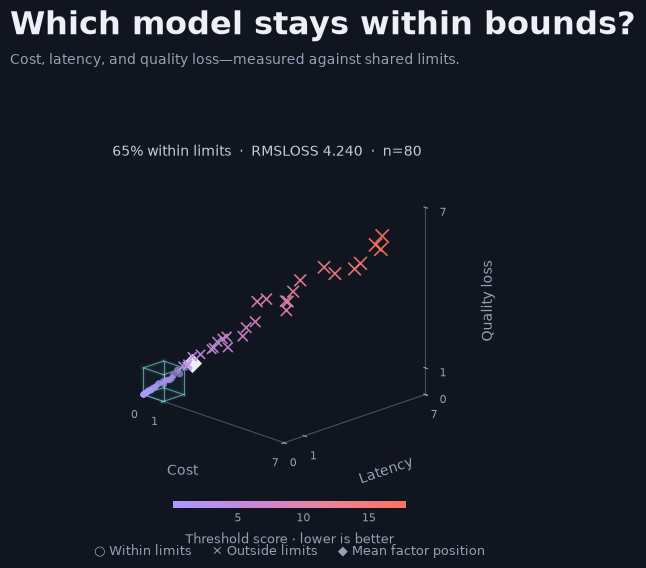

In [62]:
fig = plot_threshold_boxes_by_config(
    hero_scored,
    config_col="config",
    axes=("cost_loss", "latency_loss", "quality_loss"),
    score_col="threshold_score",
    agg_name="RMSLoss",
    agg_func=RMSLoss,
    view="threshold_corner",#threshold_corner, oblique
    max_axis=7.0,
)

Here we show the weigthed losses instead of the normalized loss factors.  This factors in both the lambda (factor weights) and k (how steeply losses increase outside the box).  As you can see, for the same score points, the loss increases significantly.  Note the scale goes to 7

In [172]:
summary = (
    hero_scored
    .groupby("config")
    .agg(
        traces=("trace_id", "count"),
        RMSL=("threshold_score",RMSLoss),
        mean_score=("threshold_score", "mean"),
        median_score=("threshold_score", "median"),
        inside_box_rate=("inside_box", "mean"),
        mean_cost=("cost_x", "mean"),
        mean_latency=("latency_x", "mean"),
        mean_quality=("quality_x", "mean"),
    )
    .sort_values(["inside_box_rate", "mean_score"], ascending=[False, True])
)
summary

,traces,RMSL,mean_score,median_score,inside_box_rate,mean_cost,mean_latency,mean_quality
config,,,,,,,,
,80,4.240362,3.608177,0.930296,0.5375,0.900683,0.896294,0.899839
